<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X2c_vetores2d_edo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio II (c): o projétil com arrasto

## Cinemática e dinâmica no plano, o arrasto que mistura as coordenadas, Runge–Kutta, e a incerteza que deixa de ser gaussiana

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 2](X2_vetores2d.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X2_vetores2d.ipynb)) · **Anterior:** [X2b_vetores2d_sistemas.ipynb](X2b_vetores2d_sistemas.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X2b_vetores2d_sistemas.ipynb)) · **Próximo:** [X2d_vetores2d_perseguicao.ipynb](X2d_vetores2d_perseguicao.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X2d_vetores2d_perseguicao.ipynb))

**Objetivo.** Descrever o voo de uma bola no plano vertical, com três modelos de cada vez mais realistas:
- **sem arrasto:** as duas coordenadas são independentes, e tudo tem fórmula fechada;
- **arrasto linear** (força proporcional à velocidade): as coordenadas **continuam** independentes, e o `sympy` ainda resolve tudo;
- **arrasto quadrático** (força proporcional ao **quadrado** da velocidade, o arrasto real de uma bola no ar): o módulo da velocidade, $\|\mathbf v\|=\sqrt{v_x^2+v_y^2}$, **mistura** as coordenadas, a fórmula fechada desaparece, e o caminho é Runge–Kutta.

Depois, a mesma dinâmica é usada para uma pergunta que leva direto ao filtro de Kalman: se o lançamento é incerto, onde a bola estará? A resposta linearizada é uma elipse; a verdadeira, para incertezas grandes, é uma "banana".

**A bola.** Uma bola de tênis de mesa, como no notebook II(b): $m=2{,}7$ g, raio $R=2$ cm. É leve e grande para a massa, e por isso o arrasto é forte: um bom exemplo para ver o efeito dele.

**Roteiro**
1. Cinemática no plano, sem arrasto
2. Arrasto linear: as coordenadas continuam separadas
3. Arrasto quadrático: as coordenadas se misturam
4. Alcance e ângulo ótimo
5. Propagar a incerteza: a elipse e a banana
6. Espaço de estados no plano: $\mathbf F$ e $\mathbf Q$ para a etapa (d)
7. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido, dtype=float), np.asarray(esperado, dtype=float)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import sympy as sp
from scipy.linalg import expm
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar
rng = np.random.default_rng(23)

G = 9.81                                        # m/s²
M_BOLA, R_BOLA, RHO_AR, CD = 2.7e-3, 0.02, 1.2, 0.5
C_ARR = 0.5 * RHO_AR * CD * np.pi * R_BOLA**2   # força de arrasto = C_ARR·|v|², contra a velocidade
K_ARR = C_ARR / M_BOLA                          # aceleração de arrasto por (m/s)²
V_TERM = np.sqrt(G / K_ARR)                     # velocidade terminal: arrasto = peso
print(f"coeficiente de arrasto por massa k = {K_ARR:.4f} 1/m;  velocidade terminal = {V_TERM:.2f} m/s")

coeficiente de arrasto por massa k = 0.1396 1/m;  velocidade terminal = 8.38 m/s


---

## 1. Cinemática no plano, sem arrasto

A posição é um **vetor** $\mathbf r(t)=(x(t),y(t))$, a velocidade é $\mathbf v=\dot{\mathbf r}$ e a aceleração é $\mathbf a=\ddot{\mathbf r}$. Sem ar, a única força é o peso, e a aceleração é constante: $\mathbf a=(0,-g)$. Cada coordenada é um movimento do notebook I(c): uniforme em $x$, uniformemente variado em $y$. O `sympy` integra as duas, elimina o tempo para obter a **trajetória** $y(x)$ (uma parábola), e encontra o alcance e o ângulo que o maximiza.

In [2]:
t, v0, th, g, xx = sp.symbols("t v_0 theta g x", positive=True)
vx0, vy0 = v0 * sp.cos(th), v0 * sp.sin(th)
x_t = sp.integrate(vx0, (t, 0, t))
y_t = sp.integrate(vy0 + sp.integrate(-g, (t, 0, t)), (t, 0, t))
print("x(t) =", x_t, ";   y(t) =", sp.expand(y_t))
t_de_x = sp.solve(sp.Eq(x_t, xx), t)[0]
print("trajetória: y(x) =", sp.simplify(y_t.subs(t, t_de_x)), "  ← uma parábola em x")
t_voo = [s for s in sp.solve(sp.Eq(y_t, 0), t) if s != 0][0]
alcance = sp.simplify(x_t.subs(t, t_voo))
print("tempo de voo =", t_voo, ";   alcance =", alcance)
print("alcance − v₀² sen(2θ)/g =", sp.simplify(alcance - v0**2 * sp.sin(2 * th) / g))
th_otimo = sp.solve(sp.diff(alcance, th), th)
print("ângulos em que d(alcance)/dθ = 0:", th_otimo, "=", [sp.deg(a) for a in th_otimo], "graus  (135° é o lançamento para trás: o alcance mais negativo)")

x(t) = t*v_0*cos(theta) ;   y(t) = -g*t**2/2 + t*v_0*sin(theta)


trajetória: y(x) = -g*x**2/(2*v_0**2*cos(theta)**2) + x*tan(theta)   ← uma parábola em x
tempo de voo = 2*v_0*sin(theta)/g ;   alcance = v_0**2*sin(2*theta)/g
alcance − v₀² sen(2θ)/g = 0


ângulos em que d(alcance)/dθ = 0: [pi/4, 3*pi/4] = [45, 135] graus  (135° é o lançamento para trás: o alcance mais negativo)


---

## 2. Arrasto linear: as coordenadas continuam separadas

Um modelo simples de resistência do ar é uma força **proporcional à velocidade** e contrária a ela, $-b\mathbf v$. Com $\tau=m/b$ (a constante de tempo do arrasto), a segunda lei de Newton dá

$$\dot v_x=-\frac{v_x}{\tau},\qquad \dot v_y=-g-\frac{v_y}{\tau}.$$

Cada equação envolve **uma** coordenada só: o arrasto linear não mistura $x$ e $y$. São duas cópias do bloco com atrito viscoso do notebook I(c), e o `sympy` resolve cada uma. As soluções são as fórmulas usadas para mirar o projétil no notebook II(b). Quando $t\to\infty$, a velocidade vertical tende a $-g\tau$: a **velocidade terminal**, em que o arrasto equilibra o peso.

In [3]:
tau = sp.Symbol("tau", positive=True)
vx, vy, X, Y = sp.Function("v_x"), sp.Function("v_y"), sp.Function("x"), sp.Function("y")
sol_vx = sp.dsolve(sp.Eq(vx(t).diff(t), -vx(t) / tau), ics={vx(0): vx0}).rhs
sol_vy = sp.dsolve(sp.Eq(vy(t).diff(t), -g - vy(t) / tau), ics={vy(0): vy0}).rhs
x_lin = sp.integrate(sol_vx.subs(t, sp.Symbol("s")), (sp.Symbol("s"), 0, t))
y_lin = sp.integrate(sol_vy.subs(t, sp.Symbol("s")), (sp.Symbol("s"), 0, t))
print("v_x(t) =", sp.simplify(sol_vx), ";   v_y(t) =", sp.simplify(sol_vy))
print("x(t) =", sp.simplify(x_lin)); print("y(t) =", sp.simplify(y_lin))
print("velocidade vertical terminal:", sp.limit(sol_vy, t, sp.oo))

# as fórmulas do notebook II(b)
x_b = v0 * sp.cos(th) * tau * (1 - sp.exp(-t / tau))
y_b = -g * tau * t + (v0 * sp.sin(th) + g * tau) * tau * (1 - sp.exp(-t / tau))
print("diferença para as fórmulas do notebook II(b):", sp.simplify(x_lin - x_b), ",", sp.simplify(y_lin - y_b))
print("sem arrasto (τ → ∞), y(t) →", sp.limit(y_lin, tau, sp.oo))

v_x(t) = v_0*exp(-t/tau)*cos(theta) ;   v_y(t) = (-g*tau*exp(t/tau) + g*tau + v_0*sin(theta))*exp(-t/tau)
x(t) = tau*v_0*(exp(t/tau) - 1)*exp(-t/tau)*cos(theta)
y(t) = tau*(-g*tau - v_0*sin(theta) + (-g*t + g*tau + v_0*sin(theta))*exp(t/tau))*exp(-t/tau)
velocidade vertical terminal: -g*tau
diferença para as fórmulas do notebook II(b): 0 , 0


sem arrasto (τ → ∞), y(t) → -g*t**2/2 + t*v_0*sin(theta)


---

## 3. Arrasto quadrático: as coordenadas se misturam

Para uma bola no ar, a velocidades de metros por segundo, o arrasto é proporcional ao **quadrado** da velocidade: módulo $c\|\mathbf v\|^2$, direção contrária a $\mathbf v$. Com $k=c/m$,

$$\dot{\mathbf v}=-g\,\hat{\mathbf y}-k\,\|\mathbf v\|\,\mathbf v\qquad\Longleftrightarrow\qquad \dot v_x=-k\sqrt{v_x^2+v_y^2}\;v_x,\quad \dot v_y=-g-k\sqrt{v_x^2+v_y^2}\;v_y .$$

Agora a equação de $v_x$ depende de $v_y$, e vice-versa: o **módulo** da velocidade acopla as coordenadas. Não há solução fechada geral.

**Um caso com solução: a queda vertical.** Se $v_x=0$, sobra $\dot v=-g+kv^2$ (com $v<0$ descendo). A solução partindo do repouso é $v(t)=-v_T\tanh(gt/v_T)$, com $v_T=\sqrt{g/k}$. O `sympy` não consegue impor a condição inicial nesta equação (o `dsolve` devolve um erro), mas **conferir** uma solução é muito mais fácil que encontrá-la: basta substituí-la na equação. É uma boa estratégia geral, e é o que a célula faz.

In [4]:
k_s, vT = sp.symbols("k v_T", positive=True)
v_cand = -vT * sp.tanh(g * t / vT)
eq = v_cand.diff(t) - (-g + k_s * v_cand**2)
print("resíduo da equação com v = −v_T tanh(gt/v_T):", sp.simplify(eq.subs(vT, sp.sqrt(g / k_s))))
print("v(0) =", v_cand.subs(t, 0), ";   v(∞) =", sp.limit(v_cand, t, sp.oo))
y_queda = sp.integrate(v_cand.subs(t, sp.Symbol("s")), (sp.Symbol("s"), 0, t))
print("altura perdida: y(t) =", sp.simplify(y_queda))
v_queda = sp.lambdify(t, v_cand.subs({vT: V_TERM, g: G}), "numpy")
y_queda_num = sp.lambdify(t, y_queda.subs({vT: V_TERM, g: G}), "numpy")
print(f"bola de tênis de mesa: depois de 1 s de queda, v = {v_queda(1.0):.3f} m/s (no vácuo, {-G:.2f});"
      f" caiu {-y_queda_num(1.0):.3f} m (no vácuo, {G / 2:.3f})")

resíduo da equação com v = −v_T tanh(gt/v_T): 0
v(0) = 0 ;   v(∞) = -v_T


altura perdida: y(t) = -t*v_T + v_T**2*log(tanh(g*t/v_T) + 1)/g
bola de tênis de mesa: depois de 1 s de queda, v = -6.910 m/s (no vácuo, -9.81); caiu 4.076 m (no vácuo, 4.905)


**Runge–Kutta no plano.** O RK4 do notebook I(c) funciona sem mudar uma linha: o estado agora é o vetor $(x,y,v_x,v_y)$, e as inclinações $\mathbf k_i$ são vetores de quatro componentes. A célula confere duas coisas:
- a **ordem**: na queda vertical, contra a solução exata do `tanh`; no voo oblíquo, contra uma solução de referência do `scipy` com tolerância de $10^{-13}$;
- o **balanço de energia**. O arrasto dissipa energia à taxa $\dot E=\mathbf F_{\text{arrasto}}\cdot\mathbf v=-c\|\mathbf v\|^3$. Integrando essa taxa junto com o movimento (uma quinta componente do estado, o trabalho do arrasto $W$), deve valer $E(0)-E(t)=W(t)$ em cada instante. É uma conferência independente: um erro na força apareceria aqui.

In [5]:
def f_quad(t, s):
    """Estado s = (x, y, vx, vy, W): W acumula a energia dissipada pelo arrasto."""
    x, y, vx, vy = s[0], s[1], s[2], s[3]
    v = np.hypot(vx, vy)
    return np.array([vx, vy, -K_ARR * v * vx, -G - K_ARR * v * vy, C_ARR * v**3])

def rk4_passo(f, t, y, h):
    k1 = f(t, y); k2 = f(t + h / 2, y + h / 2 * k1); k3 = f(t + h / 2, y + h / 2 * k2); k4 = f(t + h, y + h * k3)
    return y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

def rk4(f, y0, T, h):
    y = np.array(y0, float)
    for i in range(int(round(T / h))):
        y = rk4_passo(f, i * h, y, h)
    return y

def energia(s): return 0.5 * M_BOLA * (s[2]**2 + s[3]**2) + M_BOLA * G * s[1]

hs = np.array([0.04, 0.02, 0.01, 0.005, 0.0025])
e_queda = [abs(rk4(f_quad, [0, 0, 0, 0, 0], 1.0, h)[3] - v_queda(1.0)) for h in hs]
s0 = np.array([0, 0, 15 * np.cos(np.radians(40)), 15 * np.sin(np.radians(40)), 0.0])
ref = solve_ivp(f_quad, (0, 1.0), s0, method="DOP853", rtol=1e-13, atol=1e-14).y[:, -1]
e_obliquo = [np.hypot(*(rk4(f_quad, s0, 1.0, h)[:2] - ref[:2])) for h in hs]
for nome, e in [("queda vertical (contra o tanh)", e_queda), ("voo oblíquo (contra DOP853)", e_obliquo)]:
    print(f"{nome:32s} ordem medida = {np.polyfit(np.log(hs), np.log(e), 1)[0]:.2f}")
confere("ordem do RK4 na queda ≈ 4", np.polyfit(np.log(hs), np.log(e_queda), 1)[0], 4.0, tol=0.15)
confere("ordem do RK4 no voo oblíquo ≈ 4", np.polyfit(np.log(hs), np.log(e_obliquo), 1)[0], 4.0, tol=0.15)

s, h, balanco = s0.copy(), 0.001, []
for i in range(1000):
    s = rk4_passo(f_quad, i * h, s, h)
    balanco.append(energia(s0) - energia(s) - s[4])
print(f"\nenergia inicial {1000 * energia(s0):.2f} mJ;  dissipada em 1 s: {1000 * s[4]:.2f} mJ ({100 * s[4] / energia(s0):.0f}%)")
confere("balanço de energia: E(0) − E(t) = trabalho do arrasto, em todo instante", balanco, np.zeros(1000), tol=1e-12)

queda vertical (contra o tanh)   ordem medida = 4.01
voo oblíquo (contra DOP853)      ordem medida = 4.05
OK   ordem do RK4 na queda ≈ 4:  diferença máxima = 1.33e-02
OK   ordem do RK4 no voo oblíquo ≈ 4:  diferença máxima = 5.03e-02

energia inicial 303.75 mJ;  dissipada em 1 s: 219.11 mJ (72%)
OK   balanço de energia: E(0) − E(t) = trabalho do arrasto, em todo instante:  diferença máxima = 4.19e-13


**Leitura.** O RK4 mantém a ordem 4 com o estado vetorial, nos dois testes. O balanço de energia fecha até a precisão da máquina, e mostra o tamanho do efeito: em um segundo de voo, o arrasto dissipa cerca de 72% da energia de lançamento. Uma bola de tênis de mesa é um projétil "ruim", e por isso um bom laboratório.

---

## 4. Alcance e ângulo ótimo

No vácuo, o alcance máximo é com 45° (seção 1). Com arrasto, subir muito custa caro (a bola fica mais tempo no ar, freando), e o ângulo ótimo **cai**. Para achar o alcance, é preciso o instante exato em que a bola volta à altura zero, que quase nunca coincide com o fim de um passo: o `solve_ivp` faz isso com a **detecção de eventos** (o exercício 3 do notebook I(c)). O ângulo ótimo sai de uma busca unidimensional (`minimize_scalar`).

OK   vácuo: alcance numérico = v₀² sen 2θ / g:  diferença máxima = 1.78e-15
 v₀ (m/s)   ângulo ótimo   alcance máximo   alcance no vácuo (45°)
       5         43.2°           2.02 m               2.55 m


      10         39.9°           5.26 m              10.19 m


      15         37.1°           7.91 m              22.94 m
      30         31.7°          13.00 m              91.74 m


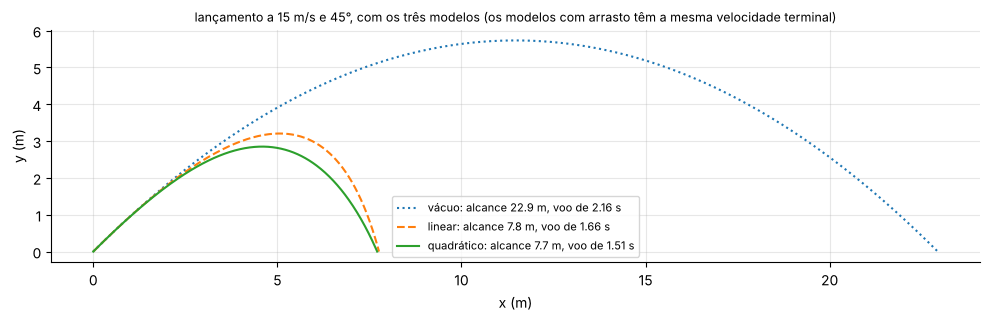

In [6]:
def voo(theta, v0, modelo="quadrático"):
    """Devolve (alcance, tempo de voo, solução) para um lançamento da origem."""
    if modelo == "vácuo":
        f = lambda t, s: np.array([s[2], s[3], 0.0, -G])
    elif modelo == "linear":                                   # mesma velocidade terminal que o quadrático
        f = lambda t, s: np.array([s[2], s[3], -s[2] * G / V_TERM, -G - s[3] * G / V_TERM])
    else:
        f = lambda t, s: f_quad(t, np.r_[s, 0.0])[:4]
    chao = lambda t, s: s[1]; chao.terminal = True; chao.direction = -1
    sol = solve_ivp(f, (0, 30), [0, 0, v0 * np.cos(theta), v0 * np.sin(theta)], events=chao,
                    rtol=1e-10, atol=1e-12, dense_output=True)
    return sol.y_events[0][0][0], sol.t_events[0][0], sol

confere("vácuo: alcance numérico = v₀² sen 2θ / g", voo(np.radians(30), 10, "vácuo")[0], 100 * np.sin(np.radians(60)) / G, tol=1e-8)

print(" v₀ (m/s)   ângulo ótimo   alcance máximo   alcance no vácuo (45°)")
for v0_ in [5.0, 10.0, 15.0, 30.0]:
    r = minimize_scalar(lambda a: -voo(a, v0_)[0], bounds=(0.1, 1.4), method="bounded", options={"xatol": 1e-7})
    print(f"{v0_:8.0f}   {np.degrees(r.x):10.1f}°   {-r.fun:12.2f} m   {v0_**2 / G:16.2f} m")

fig, ax = plt.subplots(figsize=(10, 3.8))
for modelo, estilo in [("vácuo", ":"), ("linear", "--"), ("quadrático", "-")]:
    D, T, sol = voo(np.radians(45), 15.0, modelo)
    tt = np.linspace(0, T, 300); xy = sol.sol(tt)
    ax.plot(xy[0], xy[1], estilo, label=f"{modelo}: alcance {D:.1f} m, voo de {T:.2f} s")
ax.set_aspect("equal"); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.legend(fontsize=8)
ax.set_title("lançamento a 15 m/s e 45°, com os três modelos (os modelos com arrasto têm a mesma velocidade terminal)", fontsize=9)
plt.tight_layout(); plt.show()

**Leitura.** Quanto mais rápido o lançamento, mais o arrasto pesa (ele cresce com o quadrado da velocidade), e menor fica o ângulo ótimo: perto de 45° a 5 m/s, pouco mais de 30° a 30 m/s. O alcance com arrasto fica muito abaixo do alcance no vácuo: a 30 m/s, uma fração pequena dele. A trajetória com arrasto **não é simétrica**: sobe mais inclinada do que desce, e a descida é quase vertical, porque no fim a bola está perto da velocidade terminal. O modelo linear, com a mesma velocidade terminal, acerta o alcance da figura quase por acaso (7,8 m contra 7,7 m), mas sobe mais alto e voa mais tempo. A coincidência não se mantém: a 45°, ele subestima o alcance a 5 e a 10 m/s e o superestima a 30 m/s (17,5 m contra 12,2 m). Um modelo simplificado pode acertar um número e errar o fenômeno (exercício 5).

---

## 5. Propagar a incerteza: a elipse e a banana

Um lançador humano nunca repete o mesmo lançamento: a velocidade varia um pouco, o ângulo varia um pouco. Se $(v_0,\theta)$ é uma variável aleatória, **onde a bola estará** num instante $T$ fixo? Esta é exatamente a pergunta da **predição** do filtro de Kalman: dada a incerteza do estado agora, qual é a incerteza depois?

Há duas respostas:
- **linearizada** (a do filtro de Kalman estendido): perto do lançamento nominal, a posição em $T$ é aproximadamente uma função linear de $(v_0,\theta)$, com o **jacobiano** $\mathbf J$ como matriz. A covariância se propaga como $\mathbf P_T=\mathbf J\mathbf P_0\mathbf J^\top$, e a nuvem é uma **elipse**;
- **Monte Carlo**: sortear milhares de lançamentos, simular cada um e olhar a nuvem de pontos.

O RK4 abaixo é **vetorizado**: integra 5000 lançamentos de uma vez, com o estado guardado numa matriz de 5000 linhas.

posição nominal em T = 0,6 s: [3.431 1.383]  m;   jacobiano ∂(x,y)/∂(v₀,θ):
 [[ 0.2567 -2.7026]
 [ 0.2348  3.4986]]


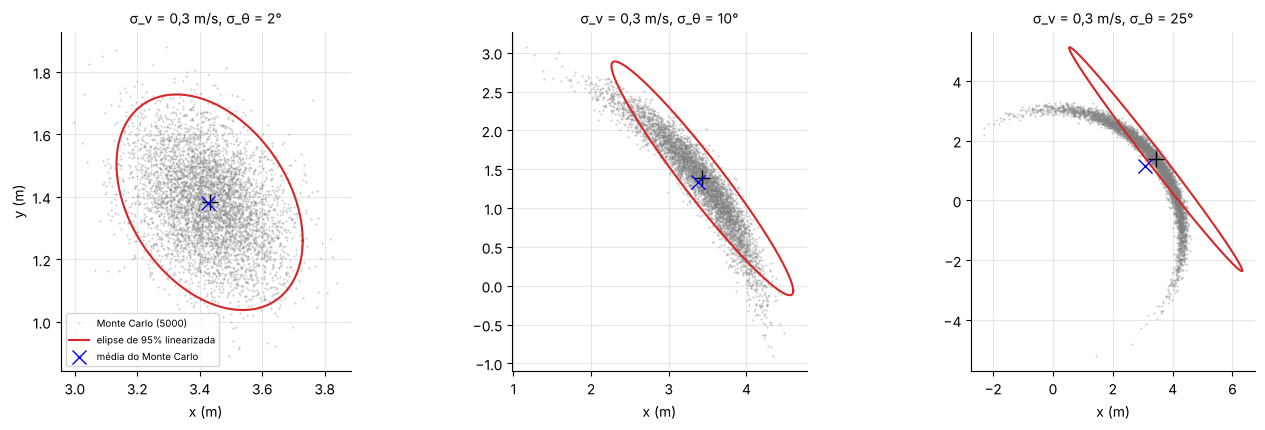

σ_θ =    2°:  covariância linearizada [[0.015, -0.006], [-0.006, 0.02]]  Monte Carlo [[0.015, -0.006], [-0.006, 0.02]]  média − nominal = [-0.004 -0.004]
σ_θ =   10°:  covariância linearizada [[0.228, -0.283], [-0.283, 0.378]]  Monte Carlo [[0.225, -0.264], [-0.264, 0.359]]  média − nominal = [-0.055 -0.042]
σ_θ =   25°:  covariância linearizada [[1.397, -1.795], [-1.795, 2.335]]  Monte Carlo [[1.387, -1.345], [-1.345, 1.974]]  média − nominal = [-0.345 -0.225]
OK   σ_θ = 2°: a covariância linearizada coincide com a de Monte Carlo:  diferença relativa máxima = 9.21e-03


In [7]:
def f_quad_vet(t, S):
    v = np.hypot(S[:, 2], S[:, 3])
    return np.column_stack([S[:, 2], S[:, 3], -K_ARR * v * S[:, 2], -G - K_ARR * v * S[:, 3]])

def posicao_em(v0s, ths, T=0.6, h=0.005):
    S = np.column_stack([np.zeros_like(v0s), np.zeros_like(v0s), v0s * np.cos(ths), v0s * np.sin(ths)])
    return rk4(f_quad_vet, S, T, h)[:, :2]

mu = np.array([10.0, np.radians(40)])
e1, e2 = np.array([1e-6, 0]), np.array([0, 1e-6])
J = np.column_stack([(posicao_em(*(mu + e)[:, None]) - posicao_em(*(mu - e)[:, None]))[0] / 2e-6 for e in (e1, e2)])
p_nom = posicao_em(*mu[:, None])[0]
print("posição nominal em T = 0,6 s:", p_nom.round(3), " m;   jacobiano ∂(x,y)/∂(v₀,θ):\n", J.round(4))

fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
tab_inc = []
for a_, sig_th in zip(ax, [2.0, 10.0, 25.0]):
    P0 = np.diag([0.3**2, np.radians(sig_th)**2])
    P_lin = J @ P0 @ J.T
    amostra = rng.multivariate_normal(mu, P0, 5000)
    nuvem = posicao_em(amostra[:, 0], amostra[:, 1])
    P_mc, desvio_media = np.cov(nuvem.T), nuvem.mean(0) - p_nom
    tab_inc.append((sig_th, P_lin, P_mc, desvio_media))
    a_.plot(*nuvem.T, ".", ms=1, alpha=.4, color="gray", label="Monte Carlo (5000)")
    ang = np.linspace(0, 2 * np.pi, 200); Lc = np.linalg.cholesky(P_lin)
    elipse = p_nom[:, None] + 2.4477 * Lc @ np.array([np.cos(ang), np.sin(ang)])
    a_.plot(*elipse, "tab:red", label="elipse de 95% linearizada")
    a_.plot(*p_nom, "k+", ms=12); a_.plot(*nuvem.mean(0), "bx", ms=10, label="média do Monte Carlo")
    a_.set_aspect("equal"); a_.set_title(f"σ_v = 0,3 m/s, σ_θ = {sig_th:.0f}°", fontsize=10); a_.set_xlabel("x (m)")
ax[0].set_ylabel("y (m)"); ax[0].legend(fontsize=7, loc="lower left"); plt.tight_layout(); plt.show()

for sig_th, P_lin, P_mc, dm in tab_inc:
    print(f"σ_θ = {sig_th:4.0f}°:  covariância linearizada {P_lin.round(3).tolist()}  Monte Carlo {P_mc.round(3).tolist()}"
          f"  média − nominal = {dm.round(3)}")
confere("σ_θ = 2°: a covariância linearizada coincide com a de Monte Carlo",
        tab_inc[0][2], tab_inc[0][1], tol=0.08, relativo=True)

**Leitura.**
- Com $\sigma_\theta=2°$, a nuvem é uma elipse e a covariância linearizada coincide com a de Monte Carlo dentro do erro estatístico: o EKF estaria certo.
- Com $\sigma_\theta=10°$, a nuvem já se curva: os pontos estão sobre um arco (todas as bolas saem com quase a mesma velocidade, e o ângulo as espalha ao longo de uma curva). A covariância ainda é parecida, mas a elipse é mais larga que a nuvem, que é fina e curva, e a média do Monte Carlo começa a se afastar do ponto nominal.
- Com $\sigma_\theta=25°$, a nuvem é uma **banana**, e a elipse cobre regiões onde não há bola nenhuma, enquanto deixa de fora as pontas da banana. A média do Monte Carlo cai na borda interna da nuvem, quase fora dela: o "ponto médio" de uma banana é um lugar onde quase não há bananas.

A banana é a mesma doença do notebook I(d), em outra forma: lá, a crença tinha duas corcovas; aqui, tem uma forma curva que nenhuma gaussiana descreve. Os remédios também são os mesmos: Monte Carlo (o **filtro de partículas** da etapa (d) é um Monte Carlo que se corrige com medidas), ou escolher **coordenadas** em que a nuvem volte a ser elipse. Em coordenadas polares (distância e ângulo), a banana se endireita. É o que os domínios com rotação farão de modo sistemático: escrever a incerteza no espaço tangente, onde ela é quase gaussiana.

---

## 6. Espaço de estados no plano: $\mathbf F$ e $\mathbf Q$ para a etapa (d)

Na etapa (d), Pepé modela Penélope no plano com o modelo mais simples, o de **velocidade quase constante** em cada eixo, com uma aceleração aleatória branca de intensidade $q$ **independente** em $x$ e em $y$. Com o estado $(x,y,v_x,v_y)$,

$$\mathbf A=\begin{bmatrix}\mathbf 0&\mathbf I\\\mathbf 0&\mathbf 0\end{bmatrix},\qquad\mathbf B=\begin{bmatrix}\mathbf 0\\\mathbf I\end{bmatrix}\qquad(\text{blocos }2\times2).$$

A função `discretiza` do notebook I(c) dá $\mathbf F$ e $\mathbf Q$. Como os dois eixos são independentes, o resultado tem de ser o do domínio I **repetido em cada eixo**: com as variáveis reordenadas como $(x,v_x,y,v_y)$, as matrizes são **bloco-diagonais**, com o bloco do domínio I em cada eixo. Em álgebra linear, isso se escreve com o produto de Kronecker: $\mathbf F_{\mathbb R^2}=\mathbf I_2\otimes\mathbf F_{\mathbb R}$.

In [8]:
def discretiza(A, B, dt, q=None):
    n, m = A.shape[0], B.shape[1]
    Maug = np.zeros((n + m, n + m)); Maug[:n, :n] = A; Maug[:n, n:] = B
    E = expm(Maug * dt); F, Gd = E[:n, :n], E[:n, n:]
    if q is None:
        return F, Gd
    V = np.zeros((2 * n, 2 * n)); V[:n, :n] = -A; V[:n, n:] = B @ B.T * q; V[n:, n:] = A.T
    W = expm(V * dt); Q = F @ W[:n, n:]
    return F, Gd, 0.5 * (Q + Q.T)

DT, Q_INT = 0.1, 1.0
F1, _, Q1 = discretiza(np.array([[0, 1.0], [0, 0]]), np.array([[0], [1.0]]), DT, Q_INT)       # domínio I
A2 = np.block([[np.zeros((2, 2)), np.eye(2)], [np.zeros((2, 2)), np.zeros((2, 2))]])
B2 = np.vstack([np.zeros((2, 2)), np.eye(2)])
F2, _, Q2 = discretiza(A2, B2, DT, Q_INT)                                                          # domínio II
ordem = [0, 2, 1, 3]                                   # (x, y, vx, vy) → (x, vx, y, vy)
print("F do plano, reordenado:\n", F2[np.ix_(ordem, ordem)], "\nQ do plano, reordenado:\n", Q2[np.ix_(ordem, ordem)])
confere("F do plano = I₂ ⊗ F da reta", F2[np.ix_(ordem, ordem)], np.kron(np.eye(2), F1), tol=1e-15)
confere("Q do plano = I₂ ⊗ Q da reta", Q2[np.ix_(ordem, ordem)], np.kron(np.eye(2), Q1), tol=1e-15)

F do plano, reordenado:
 [[1.  0.1 0.  0. ]
 [0.  1.  0.  0. ]
 [0.  0.  1.  0.1]
 [0.  0.  0.  1. ]] 
Q do plano, reordenado:
 [[0.000333 0.005    0.       0.      ]
 [0.005    0.1      0.       0.      ]
 [0.       0.       0.000333 0.005   ]
 [0.       0.       0.005    0.1     ]]
OK   F do plano = I₂ ⊗ F da reta:  diferença máxima = 0.00e+00
OK   Q do plano = I₂ ⊗ Q da reta:  diferença máxima = 0.00e+00


**Leitura.** O modelo de movimento de Pepé no plano é exatamente "dois domínios I lado a lado". Se os **sensores** também fossem independentes por eixo (uma régua que mede $x$ e $y$ com erros independentes), o filtro de Kalman do plano seria literalmente dois filtros da reta, e a etapa (d) confere isso. O plano só fica interessante quando a medida mistura os eixos: a distância $\sqrt{x^2+y^2}$ e a direção $\mathrm{atan2}(y,x)$. É o que acontece com o olfato de Pepé.

**RK4 hoje, RKMK depois.** No plano, como na reta, o RK4 só **soma** incrementos ao estado, e somar é o $\boxplus$ de ℝ². O RKMK continua igual ao RK4. A diferença chega com as rotações: no domínio IV, a rotação do plano é uma multiplicação de complexos, e o RKMK passa a compor em vez de somar.

---

## 7. Exercícios

1. **Velocidade terminal medida.** Solte a bola de 10 m de altura (com o RK4 da seção 3) e encontre o instante em que ela atinge 99% da velocidade terminal. Confira com a solução do `tanh`.
2. **Ordem com eventos.** O alcance da seção 4 é calculado com a detecção de eventos do `solve_ivp`. Implemente o mesmo com o RK4 de passo fixo, achando o instante de chegada ao chão por interpolação cúbica de Hermite entre os dois últimos passos (posição e velocidade conhecidas nos dois). Qual é a ordem do alcance assim calculado?
3. **A banana em coordenadas polares.** Repita a seção 5 com $\sigma_\theta=25°$, mas propague a incerteza da posição **em relação ao lançador** em coordenadas polares $(\rho,\varphi)$. Compare a elipse linearizada e o Monte Carlo nessas coordenadas. Que conclusão você tira para a escolha do estado de um filtro?
4. **Vento.** Acrescente um vento horizontal constante $w$ ao arrasto quadrático (o arrasto depende da velocidade **em relação ao ar**, $\mathbf v-(w,0)$). Para $v_0=10$ m/s, qual vento contrário reduz o alcance ótimo à metade? O ângulo ótimo sobe ou desce?
5. **Arrasto linear ajustado.** Escolha $\tau$ do modelo linear que minimiza a diferença de alcance para o modelo quadrático, com $v_0=10$ m/s e $\theta=40°$ (um problema de mínimos quadrados de uma variável, notebook I(b)). Com esse $\tau$, quanto o modelo linear erra para $v_0=20$ m/s?